# 国泰君安 · 尾部风险最小化配置复现

复现国泰君安数量化专题之一百零九《资产配置之步步为营：尾部风险控制与优化》
（陈奥林、叶尔乐，2018-03-12；原文取自作者公众号转载版）。

## 原文方法

1. **边缘分布**：用过去 120 个交易日的日收益，对每个资产做高斯核密度估计（KDE），独立抽样得到 K。
2. **注入相关**：对历史协方差做 Cholesky 分解 Σ = AAᵀ，用递推式
   X_i = Σ_{j<i} (K_j − μ_j)/A_jj · A_ij + K_i 构造相关的模拟收益。
   原文称「从公式的角度可以保证协方差一致」，边缘分布用逐年 KS 检验验证。
3. **风险度量**：持有期 T=20 个交易日，X_T 为期末对数收益，Y_T 为期内最低点的对数收益。
   期内风险 = P(Y_T ≤ −1%)，期末风险 = P(Y_T > −1%, X_T ≤ 1%)，**总风险 = 两者之和**。
4. **优化**：每 20 个交易日模拟 1500 条路径，求总风险最小的权重（非负、和为 1），按权重配比后持有。

## 复现口径

| 项 | 原文 | 本复现 |
|---|---|---|
| A 股 | 沪深300 | 同 |
| 港股 | 恒生指数 | 盈富基金（02800.HK，后复权；免费恒指数据仅 2013 年起，二者日收益相关 0.98） |
| 美股 | 标普500 | 同 |
| 国债 | 中债国债总财富指数 | 同（直接取自中债官网） |
| 黄金 | 上金所黄金 9999 | GLD × 美元兑人民币（免费的上金所数据仅 2016-12 起） |
| 总风险公式 | 写作 P(X_T ≤ x, Y_T ≤ y)，但随即分解为期内 + 期末，报告的数字也是二者之和 | 按「二者之一发生」计算 |
| 优化方法 | 未说明 | 权重网格穷举（两资产步长 1%，五资产步长 5%）；并列最小时取模拟期末收益更高者 |
| 持有期内 | 「按照权重进行资产配比」 | 期初配比、期内不再平衡 |
| 夏普比率 | 未说明 | 按原文数字倒推为不扣无风险利率（股债：7.06%/0.98 ≈ 7.2% 波动，与复现一致），另给扣 2% 的版本 |

## 0 · 环境与数据

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tailrisk").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, ks_2samp, skew
from tailrisk import data, simulation as sm, allocation as al, backtest as bt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})
rng = np.random.default_rng(2018)

NAMES = {"沪深300": "沪深300", "恒生指数(盈富基金)": "恒生", "标普500": "标普500",
         "中债国债总财富": "国债", "黄金(GLD×美元兑人民币)": "黄金"}
prices = data.load_prices(list(NAMES)).loc["2005-12-01":].rename(columns=NAMES)
R5 = data.to_returns(prices).dropna()
R2 = R5[["沪深300", "国债"]]
IN_SAMPLE, OUT_SAMPLE = slice("2006-07-01", "2017-12-31"), slice("2018-01-01", None)
print(f"{R5.index.min():%Y-%m-%d} ~ {R5.index.max():%Y-%m-%d}，{len(R5)} 个共同交易日")
data.data_quality(prices)[["标的", "年化收益", "年化波动", "最大回撤", "零收益占比", "唯一值占比"]]

2005-12-02 ~ 2026-10-12，4779 个共同交易日


,标的,年化收益,年化波动,最大回撤,零收益占比,唯一值占比
0,沪深300,0.079274,0.256613,-0.723038,0.000000,1.000000
1,恒生,0.024102,0.239312,-0.639191,0.063612,0.753086
2,标普500,0.091169,0.196389,-0.567754,0.000418,0.999791
3,国债,0.040578,0.022473,-0.058518,0.000000,1.000000
4,黄金,0.092305,0.185148,-0.455552,0.000000,1.000000


盈富基金的零收益占比偏高（港股最小报价单位相对价格较大），在依赖秩的尾部 Copula 估计中会有影响；
本研究用 KDE 模拟，KDE 本身会平滑这些离散值，影响有限。

---
# 1 · 递推式能否保持协方差与边缘分布？

## 1.1 已知答案的数据

人工构造三个偏态厚尾、两两相关的资产，各方法模拟 10 万次。两种对照方法都能严格保留边缘分布：
**高斯 Copula + KDE**（正态得分相关 → 多元正态 → Φ → 各资产 KDE 分位数逆变换）和
**Iman-Conover**（各列独立从 KDE 抽样，只按目标秩相关重排顺序）。

In [2]:
T = 2000
z = rng.multivariate_normal([0, 0, 0], [[1, .6, .3], [.6, 1, .4], [.3, .4, 1]], T)
H = np.exp(0.6 * z)
H = (H - H.mean(0)) / H.std(0) * np.array([.01, .02, .015])
C0 = np.cov(H, rowvar=False)
rows = []
for name, f in sm.METHODS.items():
    X = f(H, 100_000, rng)
    C = np.cov(X, rowvar=False)
    for j in range(3):
        rows.append({"方法": name, "资产": f"第{j + 1}位", "方差误差": C[j, j] / C0[j, j] - 1,
                     "峰度（真实）": kurtosis(H[:, j]), "峰度（模拟）": kurtosis(X[:, j]),
                     "KS 距离": ks_2samp(X[:, j], H[:, j]).statistic})
pd.DataFrame(rows).set_index(["方法", "资产"]).style.format(
    {"方差误差": "{:+.1%}", "峰度（真实）": "{:.2f}", "峰度（模拟）": "{:.2f}", "KS 距离": "{:.3f}"})

递推式对第 1 位资产没有影响，但第 2、3 位的方差分别被高估约三成和两成，峰度被明显稀释，
KS 距离是正确方法的 4–5 倍。两种正确方法的误差只有 KDE 带宽带来的几个百分点。

## 1.2 原文五类资产：误差有多大、落在谁身上？

每季度末取过去 120 个交易日，各方法模拟 2 万次，与窗口内的历史数据比较。
「倒序」是把资产列表倒过来排再用递推式 —— 正确的方法不应受顺序影响。

In [3]:
def distortion(R, order):
    rows = []
    for t in R.groupby(R.index.to_period("Q")).tail(1).index[1:]:
        Hw = R.loc[:t, order].tail(120).values
        C0 = np.cov(Hw, rowvar=False)
        for name, f in sm.METHODS.items():
            X = f(Hw, 20_000, rng)
            C = np.cov(X, rowvar=False)
            for j, a in enumerate(order):
                rows.append({"方法": name, "资产": a, "方差误差": C[j, j] / C0[j, j] - 1,
                             "KS 距离": ks_2samp(X[:, j], Hw[:, j]).statistic})
    return pd.DataFrame(rows)

ORDER = list(R5.columns)
d_fwd = distortion(R5.loc[IN_SAMPLE], ORDER)
d_rev = distortion(R5.loc[IN_SAMPLE], ORDER[::-1])
tbl = pd.concat({
    "方差误差（原文顺序）": d_fwd.pivot_table(index="资产", columns="方法", values="方差误差", aggfunc="median"),
    "方差误差（倒序）": d_rev.pivot_table(index="资产", columns="方法", values="方差误差", aggfunc="median"),
}, axis=1).reindex(ORDER)
tbl.style.format("{:+.1%}")

**判读**：三种方法共有约 4–9% 的方差放大，来自 KDE 带宽本身。在此之外，原文顺序下，
排在沪深300 之后、又与之相关的恒生被递推式额外高估最多（合计约 37%），标普 500、黄金约 16%；
把顺序倒过来，原本不受影响的沪深300 变成排在后面，被高估约 39%。误差落在谁身上，取决于资产在列表里的位置。

## 1.3 原文的 KS 检验为什么没发现问题？

原文按年拟合、生成与原数据等量的随机数，在 1% 水平下做两样本 KS 检验，各资产各年均不能拒绝。
这里照做一遍，并把生成的随机数增加到 2 万个对照：

In [4]:
rows = []
for year, g in R5.loc[IN_SAMPLE].groupby(R5.loc[IN_SAMPLE].index.year):
    Hy = g[ORDER].values
    for n_sim, label in [(len(Hy), "与原数据等量（原文做法）"), (20_000, "2 万个随机数")]:
        X = sm.gtja_recursion(Hy, n_sim, rng)
        for j, a in enumerate(ORDER):
            rows.append({"年份": year, "样本量": label, "资产": a, "p 值": ks_2samp(X[:, j], Hy[:, j]).pvalue})
ks = pd.DataFrame(rows)
pd.DataFrame({lab: {"检验次数": len(g), "1% 水平拒绝": int((g["p 值"] < .01).sum()), "5% 水平拒绝": int((g["p 值"] < .05).sum())}
              for lab, g in ks.groupby("样本量")}).T

,检验次数,1% 水平拒绝,5% 水平拒绝
2 万个随机数,60,2,3
与原数据等量（原文做法）,60,1,4


两种做法都几乎不拒绝。原因不在模拟数：两样本 KS 检验的功效受较小一组样本限制，也就是每年约 240 个真实观测。
下面直接计算这个检验的功效 —— 240 个正态观测与 2 万个方差被放大的正态随机数比较，1% 水平下被拒绝的概率：

In [5]:
power = {}
for ratio in [1.08, 1.15, 1.37, 2.0]:
    power[f"方差放大 {ratio - 1:.0%}"] = np.mean([
        ks_2samp(rng.standard_normal(240), rng.standard_normal(20_000) * np.sqrt(ratio)).pvalue < 0.01
        for _ in range(500)])
pd.Series(power).to_frame("KS 检验发现差异的概率").T.style.format("{:.0%}")

,方差放大 8%,方差放大 15%,方差放大 37%,方差放大 100%
KS 检验发现差异的概率,1%,1%,6%,62%


**判读**：恒生在递推式下的方差放大约 37%，每年 240 个观测时只有约 6% 的概率被发现；方差翻倍也只有约六成。
原文用逐年 KS 检验「通过」来证明边缘分布被保留，这个论证不成立 —— 检验本身没有能力发现这种程度的差异。

---
# 2 · 按原文口径复现（2006–2017）

先跑 2006-07 至 2026-10 的全区间，再拆成原文样本期（2006-07 至 2017-12）和发表之后（2018 起）。
「实际触发」按每个持有期的真实路径计算：期内最低点跌破 −1%，或期末收益不足 1%。

In [6]:
def realized_triggers(R, W, horizon, x=0.01, y=-0.01):
    rows = []
    idx = R.index
    for t, w in W.iterrows():
        i = idx.get_loc(t) + 1
        hold = R.iloc[i:i + horizon][w.index]
        logP = np.log((1 + hold).cumprod() @ w.values)
        X, Y = logP.iloc[-1], min(logP.min(), 0.0)
        ih = Y <= y
        rows.append({"date": t, "IH": ih, "EH": (not ih) and X <= x})
    df = pd.DataFrame(rows).set_index("date")
    df["TR"] = df.IH | df.EH
    return df

def summary(daily, W, R, horizon, period):
    d = daily.loc[period]
    s = bt.perf_stats(d, rf=0.0)
    trig = realized_triggers(R, W.loc[period], horizon).mean()
    return {"年化收益": s["年化收益"], "最大回撤": s["最大回撤"], "夏普（不扣无风险利率）": s["收益波动比"],
            "夏普（扣 2%）": bt.perf_stats(d)["超额夏普"],
            "实际触发总风险": trig["TR"], "其中期内": trig["IH"], "其中期末": trig["EH"]}

runs = {}
runs["股债 20日"] = sm.gtja_backtest(R2, sm.gtja_recursion, step=0.01, start="2006-07-01", seed=1)
runs["五资产 20日"] = sm.gtja_backtest(R5, sm.gtja_recursion, step=0.05, start="2006-07-01", seed=2)
runs["五资产 60日"] = sm.gtja_backtest(R5, sm.gtja_recursion, horizon=60, step=0.05, start="2006-07-01", seed=3)
HORIZON = {"股债 20日": 20, "五资产 20日": 20, "五资产 60日": 60}
DATA = {"股债 20日": R2, "五资产 20日": R5, "五资产 60日": R5}

CICC = {"股债 20日": [0.0706, -0.1258, 0.98, None, 0.6619, 0.4173, 0.2446],
        "五资产 20日": [0.1010, -0.0875, 1.45, None, 0.6043, 0.4101, 0.1942],
        "五资产 60日": [0.0756, -0.0401, 1.88, None, 0.4565, 0.2826, 0.1739]}
cols = ["年化收益", "最大回撤", "夏普（不扣无风险利率）", "夏普（扣 2%）", "实际触发总风险", "其中期内", "其中期末"]
rows = {}
for k, (d, W, _) in runs.items():
    rows[(k, "原文")] = dict(zip(cols, CICC[k]))
    rows[(k, "复现")] = summary(d, W, DATA[k], HORIZON[k], IN_SAMPLE)
rep = pd.DataFrame(rows).T[cols]
rep.style.format({c: "{:.2%}" for c in ["年化收益", "最大回撤", "实际触发总风险", "其中期内", "其中期末"]}
                 | {"夏普（不扣无风险利率）": "{:.2f}", "夏普（扣 2%）": "{:.2f}"}, na_rep="—")

In [7]:
d5 = runs["五资产 20日"][0]
yearly = d5.loc[IN_SAMPLE].groupby(d5.loc[IN_SAMPLE].index.year).apply(lambda r: (1 + r).prod() - 1)
print("五资产 20日 逐年收益（原文：2006–2017 每年为正，最低为 2012 年 3.60%）")
yearly.to_frame("复现").T.style.format("{:.2%}")

五资产 20日 逐年收益（原文：2006–2017 每年为正，最低为 2012 年 3.60%）


,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
复现,13.27%,16.24%,0.74%,4.35%,2.77%,8.23%,2.57%,9.66%,14.47%,5.10%,3.35%,16.92%


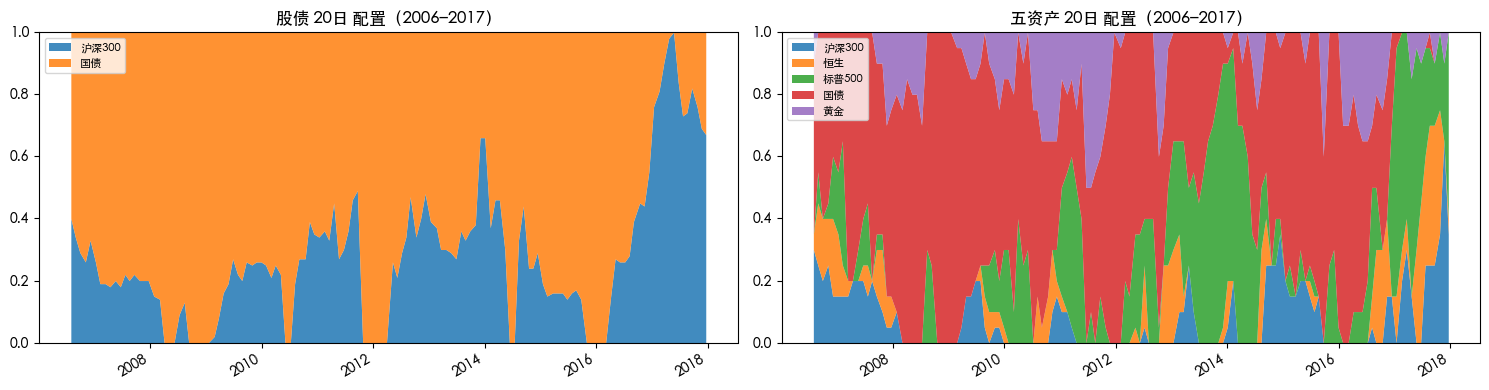

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, k in zip(axes, ["股债 20日", "五资产 20日"]):
    W = runs[k][1].loc[IN_SAMPLE]
    W.plot.area(ax=ax, lw=0, alpha=.85)
    ax.set_ylim(0, 1); ax.set_title(f"{k} 配置（2006–2017）"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**判读**：

- **股债**几乎完全复现：年化收益、最大回撤、夏普和实际触发总风险都与原文接近（期内、期末的拆分略有不同）。
- **五资产 20 日**接近：年化收益低约 1.2 个百分点，夏普 1.26 对 1.45；2006–2017 同样每年正收益，
  但最低的一年是 2008 年（0.7%），而不是原文的 2012 年（3.6%）。
- **五资产 60 日**差距较大：年化 5.8% 对 7.6%，夏普 1.44 对 1.88。
- 剩余差距可能来自数据替代（恒生用盈富基金、黄金用 GLD 换算）、原文未说明的优化方法，以及模拟的随机性。

---
# 3 · 换成正确的模拟方法，或者换个资产顺序，结果会变吗？

五资产 20 日调仓，只改变模拟方法或资产排列顺序，其余设定不变。

In [9]:
variants = {
    "递推（原文顺序）": runs["五资产 20日"],
    "递推（倒序）": sm.gtja_backtest(R5, sm.gtja_recursion, step=0.05, start="2006-07-01", seed=2, order=ORDER[::-1]),
    "高斯 Copula + KDE": sm.gtja_backtest(R5, sm.gaussian_copula_kde, step=0.05, start="2006-07-01", seed=2),
    "Iman-Conover": sm.gtja_backtest(R5, sm.iman_conover, step=0.05, start="2006-07-01", seed=2),
}
rows = {}
for name, (d, W, _) in variants.items():
    for pname, P in [("2006–2017", IN_SAMPLE), ("2018 起", OUT_SAMPLE)]:
        s = summary(d, W, R5, 20, P)
        rows[(pname, name)] = {**{k: s[k] for k in ["年化收益", "最大回撤", "夏普（不扣无风险利率）", "实际触发总风险"]},
                               **W.loc[P].mean().add_prefix("平均权重:").to_dict()}
var_tbl = pd.DataFrame(rows).T
var_tbl.style.format("{:.2%}").format("{:.2f}", subset=["夏普（不扣无风险利率）"])

,,年化收益,最大回撤,夏普（不扣无风险利率）,实际触发总风险,平均权重:沪深300,平均权重:恒生,平均权重:标普500,平均权重:国债,平均权重:黄金
2006–2017,递推（原文顺序）,8.89%,-7.80%,1.26,65.91%,8.14%,6.67%,21.14%,53.30%,10.76%
2018 起,递推（原文顺序）,8.19%,-10.94%,1.11,63.00%,7.70%,1.90%,21.05%,48.00%,21.35%
2006–2017,递推（倒序）,8.95%,-7.37%,1.29,64.39%,6.17%,7.88%,21.97%,52.12%,11.86%
2018 起,递推（倒序）,8.33%,-9.79%,1.15,63.00%,4.15%,3.15%,22.15%,47.65%,22.90%
2006–2017,高斯 Copula + KDE,9.12%,-8.79%,1.26,64.39%,7.39%,7.77%,22.27%,51.10%,11.48%
2018 起,高斯 Copula + KDE,9.15%,-10.57%,1.25,67.00%,5.50%,3.35%,20.90%,47.40%,22.85%
2006–2017,Iman-Conover,8.82%,-9.51%,1.22,64.39%,7.46%,7.46%,22.16%,51.21%,11.70%
2018 起,Iman-Conover,8.18%,-10.78%,1.09,61.00%,5.40%,2.75%,22.35%,46.40%,23.10%


In [10]:
ref = variants["高斯 Copula + KDE"][1]
pd.DataFrame({name: {"与高斯 Copula 的平均权重差（单边）": (W - ref.reindex(W.index)).abs().sum(axis=1).mean() / 2}
              for name, (_, W, _) in variants.items() if name != "高斯 Copula + KDE"}).T.style.format("{:.1%}")

,与高斯 Copula 的平均权重差（单边）
递推（原文顺序）,9.5%
递推（倒序）,9.0%
Iman-Conover,8.4%


**判读**：递推式与高斯 Copula 的平均权重差约 9.5%，而 Iman-Conover 与高斯 Copula 这两种都正确的方法之间也差约 8.4%
—— 权重差异主要是蒙特卡洛噪声，递推式额外造成的偏差很小。汇总的收益、回撤和实际触发比例也相近。
在这五类相关性较低的资产上，递推式的缺陷对最终结果影响有限。

---
# 4 · 原文发表之后（2018 起）

In [11]:
port_b, w_b = al.rolling_backtest(R5, {"等权": al.equal_weights,
                                      "最小方差": lambda W: al.min_variance(W, upper=1.0)}, lookback=120)
rows = {}
for k in ["股债 20日", "五资产 20日", "五资产 60日"]:
    d, W, _ = runs[k]
    rows[k] = summary(d, W, DATA[k], HORIZON[k], OUT_SAMPLE)
for name in port_b:
    s = bt.perf_stats(port_b[name].loc[OUT_SAMPLE], rf=0.0)
    rows[f"对照：{name}（月度调仓）"] = {"年化收益": s["年化收益"], "最大回撤": s["最大回撤"],
                                  "夏普（不扣无风险利率）": s["收益波动比"],
                                  "夏普（扣 2%）": bt.perf_stats(port_b[name].loc[OUT_SAMPLE])["超额夏普"]}
bond = R5["国债"].loc[OUT_SAMPLE]
s = bt.perf_stats(bond, rf=0.0)
rows["对照：国债指数"] = {"年化收益": s["年化收益"], "最大回撤": s["最大回撤"], "夏普（不扣无风险利率）": s["收益波动比"],
                    "夏普（扣 2%）": bt.perf_stats(bond)["超额夏普"]}
oos = pd.DataFrame(rows).T[cols]
oos.style.format({c: "{:.2%}" for c in ["年化收益", "最大回撤", "实际触发总风险", "其中期内", "其中期末"]}
                 | {"夏普（不扣无风险利率）": "{:.2f}", "夏普（扣 2%）": "{:.2f}"}, na_rep="—")

,年化收益,最大回撤,夏普（不扣无风险利率）,夏普（扣 2%）,实际触发总风险,其中期内,其中期末
股债 20日,2.16%,-13.84%,0.33,0.02,79.00%,43.00%,36.00%
五资产 20日,8.19%,-10.94%,1.11,0.84,63.00%,39.00%,24.00%
五资产 60日,5.75%,-6.06%,1.55,1.01,39.39%,24.24%,15.15%
对照：等权（月度调仓）,7.43%,-19.30%,0.73,0.53,—,—,—
对照：最小方差（月度调仓）,5.51%,-2.32%,3.06,1.95,—,—,—
对照：国债指数,5.13%,-4.13%,2.69,1.64,—,—,—


**判读**：

- **股债**在原文发表后几乎失效：年化 2.2%，远低于直接持有国债指数的 5.1%，夏普 0.33 对 2.69。
- **五资产 20 日**年化 8.2%，收益高于国债和最小方差，但最大回撤 −10.9%，比样本内更深，夏普 1.11 不如二者。
- **五资产 60 日**年化 5.8%，与最小方差、国债相当，但回撤更大、夏普更低。
- 按风险调整后的表现看，简单的最小方差组合和国债指数都更好。

In [12]:
y_oos = d5.loc[OUT_SAMPLE].groupby(d5.loc[OUT_SAMPLE].index.year).apply(lambda r: (1 + r).prod() - 1)
print("五资产 20日 逐年收益（2018 起；2026 年截至 10 月）")
y_oos.to_frame("复现").T.style.format("{:.2%}")

五资产 20日 逐年收益（2018 起；2026 年截至 10 月）


,2018,2019,2020,2021,2022,2023,2024,2025,2026
复现,0.71%,9.03%,3.33%,12.19%,-1.93%,6.37%,17.69%,16.24%,5.16%


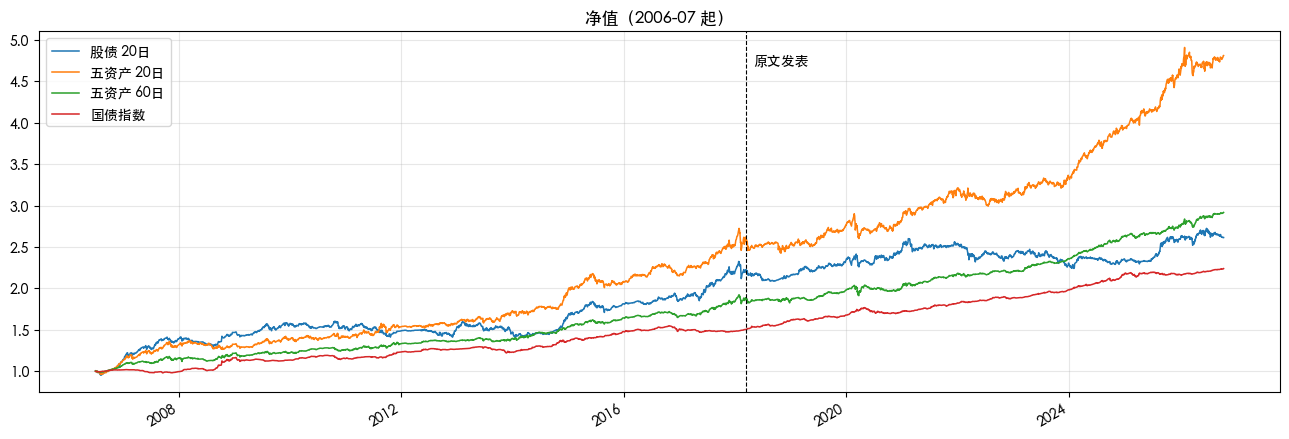

In [13]:
nav = pd.DataFrame({k: (1 + runs[k][0]).cumprod() for k in runs})
nav["国债指数"] = (1 + R5["国债"].loc[nav.index.min():]).cumprod()
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, lw=1.1)
ax.axvline(pd.Timestamp("2018-03-12"), color="k", ls="--", lw=.8)
ax.text(pd.Timestamp("2018-05-01"), ax.get_ylim()[1] * .95, "原文发表", va="top")
ax.set_title("净值（2006-07 起）"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# 结论

| 问题 | 结论 |
|---|---|
| 原文结果能否复现（2006–2017） | **基本可以**。股债几乎完全复现；五资产 20 日接近（年化 8.9% 对 10.1%，每年正收益）；60 日差距较大 |
| 递推式能否保持协方差与边缘分布 | **不能**，而且误差依赖资产排列顺序；原文的逐年 KS 检验功效太低，发现不了这种程度的差异 |
| 递推式的缺陷是否影响结果 | **在这五类资产上影响很小**：与正确方法的权重差异和蒙特卡洛噪声相当，汇总表现相近 |
| 原文发表后（2018 起） | **明显变差**。股债年化仅 2.2%；五资产 20 日在 2022 年出现负收益，打破「每年为正」；风险调整后不如最小方差组合和国债指数 |

下方为自动汇总的关键数字。

In [14]:
r = rep
for k in runs:
    print(f"{k}：原文年化 {r.loc[(k, '原文'), '年化收益']:.2%} / 复现 {r.loc[(k, '复现'), '年化收益']:.2%}；"
          f"原文夏普 {r.loc[(k, '原文'), '夏普（不扣无风险利率）']:.2f} / 复现 {r.loc[(k, '复现'), '夏普（不扣无风险利率）']:.2f}；"
          f"样本外年化 {oos.loc[k, '年化收益']:.2%}，夏普 {oos.loc[k, '夏普（不扣无风险利率）']:.2f}")
print(f"KS（与原数据等量）1% 水平拒绝 {int((ks[ks['样本量'].str.startswith('与')]['p 值'] < .01).sum())} 次；"
      f"2 万个随机数时拒绝 {int((ks[ks['样本量'].str.startswith('2')]['p 值'] < .01).sum())} 次（各 {len(ks) // 2} 次检验）")

股债 20日：原文年化 7.06% / 复现 7.51%；原文夏普 0.98 / 复现 1.07；样本外年化 2.16%，夏普 0.33
五资产 20日：原文年化 10.10% / 复现 8.89%；原文夏普 1.45 / 复现 1.26；样本外年化 8.19%，夏普 1.11
五资产 60日：原文年化 7.56% / 复现 5.79%；原文夏普 1.88 / 复现 1.44；样本外年化 5.75%，夏普 1.55
KS（与原数据等量）1% 水平拒绝 1 次；2 万个随机数时拒绝 2 次（各 60 次检验）
